In [2]:
import pandas as pd

In [3]:
df = pd.read_csv('laptop.csv', encoding='windows-1251')

In [4]:
df.head()

,laptop_ID,Company,Product,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price_euros
0,1,Apple,MacBook Pro,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 2.3GHz,8GB,128GB SSD,Intel Iris Plus Graphics 640,macOS,1.37kg,1339.69
1,2,Apple,Macbook Air,Ultrabook,13.3,1440x900,Intel Core i5 1.8GHz,8GB,128GB Flash Storage,Intel HD Graphics 6000,macOS,1.34kg,898.94
2,3,HP,250 G6,Notebook,15.6,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,8GB,256GB SSD,Intel HD Graphics 620,No OS,1.86kg,575.00
3,4,Apple,MacBook Pro,Ultrabook,15.4,IPS Panel Retina Display 2880x1800,Intel Core i7 2.7GHz,16GB,512GB SSD,AMD Radeon Pro 455,macOS,1.83kg,2537.45
4,5,Apple,MacBook Pro,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 3.1GHz,8GB,256GB SSD,Intel Iris Plus Graphics 650,macOS,1.37kg,1803.60


In [10]:
price = df.groupby(["Company", "TypeName"])["Price_euros"].mean()

In [11]:
price.head()

Company  TypeName          
Acer     2 in 1 Convertible     698.751250
         Gaming                1468.125000
         Netbook                306.000000
         Notebook               540.139744
         Ultrabook              890.500000
Name: Price_euros, dtype: float64

In [13]:
price = price.round(2)
price.head(10)

Company  TypeName          
Acer     2 in 1 Convertible     698.75
         Gaming                1468.12
         Netbook                306.00
         Notebook               540.14
         Ultrabook              890.50
Apple    Ultrabook             1564.20
Asus     2 in 1 Convertible     976.39
         Gaming                1720.01
         Netbook                266.20
         Notebook               627.10
Name: Price_euros, dtype: float64

In [14]:
price.loc["Dell"]

TypeName
2 in 1 Convertible    1131.67
Gaming                1918.39
Netbook                519.50
Notebook               870.96
Ultrabook             1477.92
Workstation           2219.17
Name: Price_euros, dtype: float64

In [16]:
price.loc["HP"]

TypeName
2 in 1 Convertible    1506.81
Gaming                1424.08
Netbook               1006.67
Notebook               816.63
Ultrabook             1537.14
Workstation           2299.68
Name: Price_euros, dtype: float64

In [18]:
price.loc[("HP", "Gaming")]

np.float64(1424.08)

In [20]:
price.xs("Gaming", level="TypeName")

Company
Acer      1468.12
Asus      1720.01
Dell      1918.39
HP        1424.08
Lenovo    1328.97
MSI       1728.91
Razer     4119.00
Name: Price_euros, dtype: float64

In [21]:
table = price.reset_index()
table

,Company,TypeName,Price_euros
0,Acer,2 in 1 Convertible,698.75
1,Acer,Gaming,1468.12
2,Acer,Netbook,306.00
3,Acer,Notebook,540.14
4,Acer,Ultrabook,890.50
5,Apple,Ultrabook,1564.20
6,Asus,2 in 1 Convertible,976.39
7,Asus,Gaming,1720.01
8,Asus,Netbook,266.20
9,Asus,Notebook,627.10


In [22]:
wide_table = price.unstack("TypeName")
wide_table

TypeName,2 in 1 Convertible,Gaming,Netbook,Notebook,Ultrabook,Workstation
Company,,,,,,
Acer,698.75,1468.12,306.00,540.14,890.50,NaN
Apple,NaN,NaN,NaN,NaN,1564.20,NaN
Asus,976.39,1720.01,266.20,627.10,1290.24,NaN
Chuwi,NaN,NaN,NaN,314.30,NaN,NaN
Dell,1131.67,1918.39,519.50,870.96,1477.92,2219.17
Fujitsu,NaN,NaN,NaN,729.00,NaN,NaN
Google,NaN,NaN,NaN,NaN,1677.67,NaN
HP,1506.81,1424.08,1006.67,816.63,1537.14,2299.68
Huawei,NaN,NaN,NaN,NaN,1424.00,NaN


In [23]:
# matplotlib

In [24]:
import matplotlib.pyplot as plt

In [26]:
first_prices = df['Price_euros'].head(3)
first_prices

0    1339.69
1     898.94
2     575.00
Name: Price_euros, dtype: float64

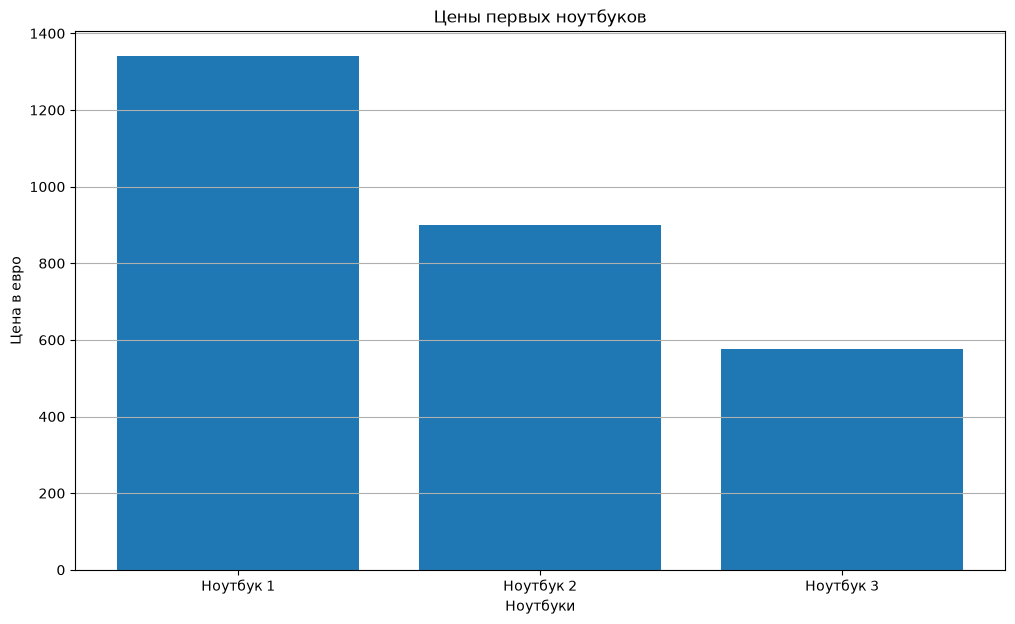

In [38]:
fig, ax = plt.subplots(figsize=(12, 7))
ax.bar(
    ["Ноутбук 1", "Ноутбук 2", "Ноутбук 3"],
    first_prices,
)
ax.set_title("Цены первых ноутбуков")
ax.set_xlabel("Ноутбуки")
ax.set_ylabel("Цена в евро")
ax.grid(True, axis="y")
plt.show()

In [39]:
# Гистограмма

In [40]:
prices = df['Price_euros']

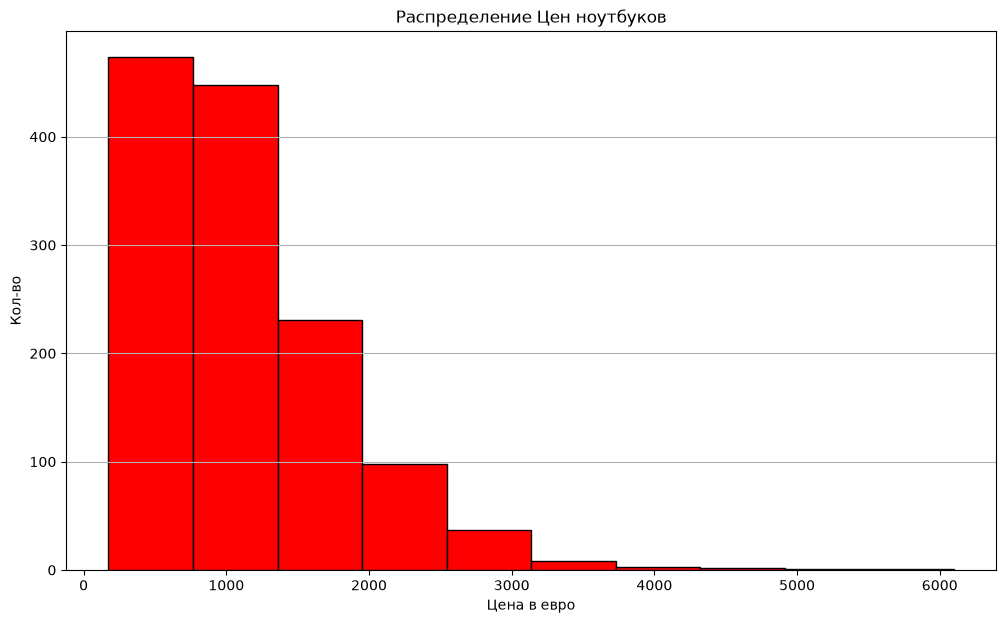

In [42]:
fig, ax = plt.subplots(figsize=(12, 7))
ax.hist(
    prices,
    bins=10,
    color="red",
    edgecolor="black",
)
ax.set_title("Распределение Цен ноутбуков")
ax.set_xlabel("Цена в евро")
ax.set_ylabel("Кол-во")
ax.grid(True, axis="y")
plt.show()

In [44]:
company_counts = df["Company"].value_counts()
company_counts

Company
Dell         297
Lenovo       297
HP           274
Asus         158
Acer         103
MSI           54
Toshiba       48
Apple         21
Samsung        9
Razer          7
Mediacom       7
Microsoft      6
Xiaomi         4
Vero           4
Chuwi          3
Google         3
Fujitsu        3
LG             3
Huawei         2
Name: count, dtype: int64

In [45]:
top_companies = company_counts.head(7)
top_companies

Company
Dell       297
Lenovo     297
HP         274
Asus       158
Acer       103
MSI         54
Toshiba     48
Name: count, dtype: int64

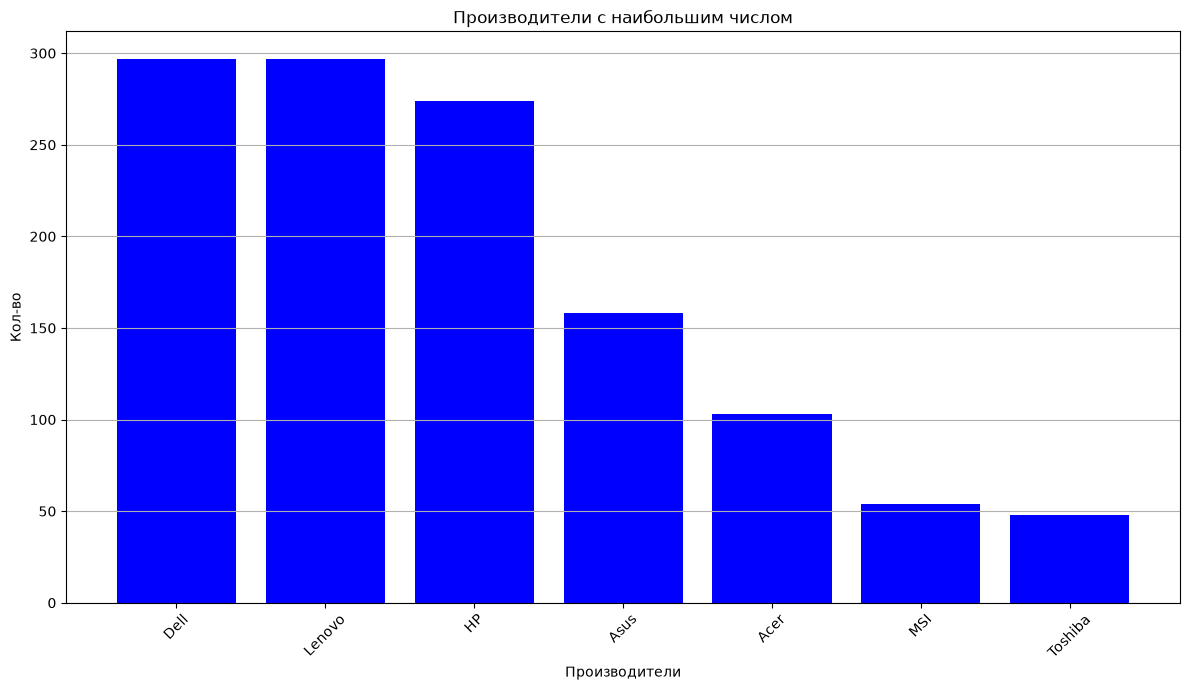

In [52]:
fig, ax = plt.subplots(figsize=(12, 7))
ax.bar(
    top_companies.index,
    top_companies.values,
    color="blue",
)

ax.set_title("Производители с наибольшим числом")
ax.set_xlabel("Производители")
ax.set_ylabel("Кол-во")

ax.tick_params(axis="x", labelrotation=45)
ax.grid(True, axis="y")
fig.tight_layout()
plt.show()

In [53]:
# Круговая диаграмма

In [56]:
os_counts = df["OpSys"].value_counts()
os_counts

OpSys
Windows 10      1072
No OS             66
Linux             62
Windows 7         45
Chrome OS         27
macOS             13
Mac OS X           8
Windows 10 S       8
Android            2
Name: count, dtype: int64

In [57]:
os_for_pie = os_counts.head(4).copy()

In [58]:
other_count = os_counts.iloc[4:].sum()
other_count


np.int64(58)

In [59]:
os_for_pie.loc["Other"] = other_count

In [60]:
os_for_pie

OpSys
Windows 10    1072
No OS           66
Linux           62
Windows 7       45
Other           58
Name: count, dtype: int64

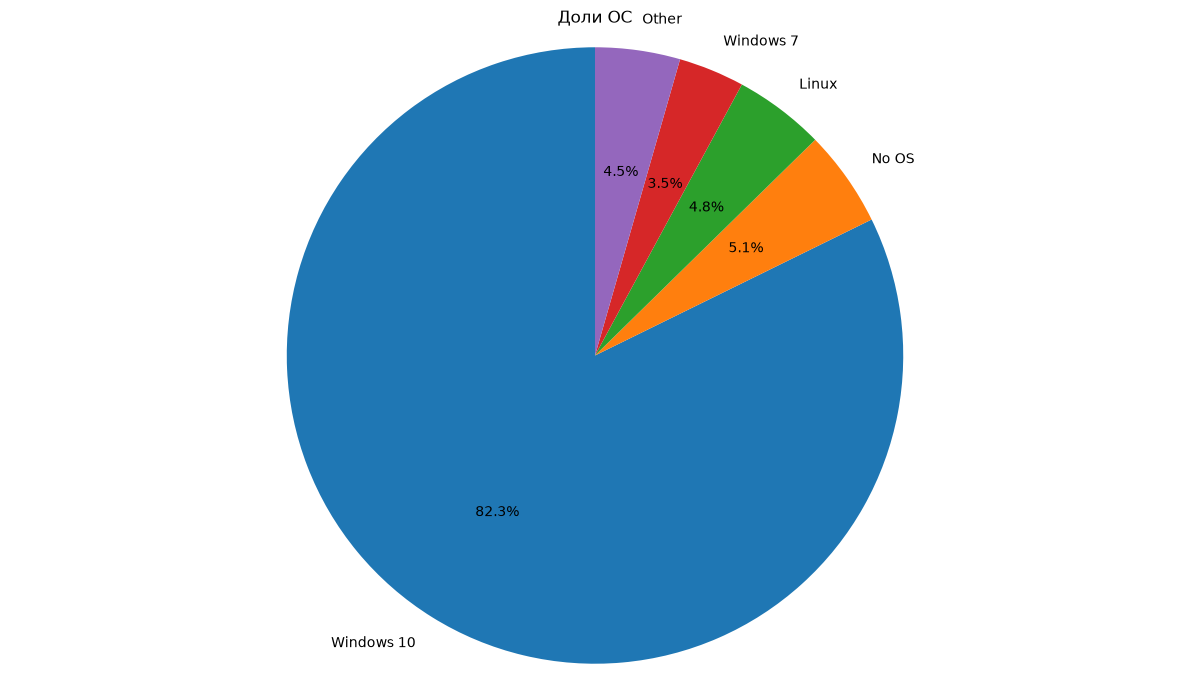

In [66]:
fig, ax = plt.subplots(figsize=(12, 7))
ax.pie(
    os_for_pie.values,
    labels=os_for_pie.index,
    autopct="%1.1f%%",
    startangle=90,
)

ax.set_title("Доли ОС")
ax.axis("equal")

fig.tight_layout()
plt.show()

In [67]:
# Точечная диаграмма

In [68]:
df["Weight_kg"] = df["Weight"].str.replace("kg", "").astype(float)
df.head()

,laptop_ID,Company,Product,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price_euros,Weight_kg
0,1,Apple,MacBook Pro,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 2.3GHz,8GB,128GB SSD,Intel Iris Plus Graphics 640,macOS,1.37kg,1339.69,1.37
1,2,Apple,Macbook Air,Ultrabook,13.3,1440x900,Intel Core i5 1.8GHz,8GB,128GB Flash Storage,Intel HD Graphics 6000,macOS,1.34kg,898.94,1.34
2,3,HP,250 G6,Notebook,15.6,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,8GB,256GB SSD,Intel HD Graphics 620,No OS,1.86kg,575.00,1.86
3,4,Apple,MacBook Pro,Ultrabook,15.4,IPS Panel Retina Display 2880x1800,Intel Core i7 2.7GHz,16GB,512GB SSD,AMD Radeon Pro 455,macOS,1.83kg,2537.45,1.83
4,5,Apple,MacBook Pro,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 3.1GHz,8GB,256GB SSD,Intel Iris Plus Graphics 650,macOS,1.37kg,1803.60,1.37


In [69]:
notebooks = df[df["TypeName"] == "Notebook"]
notebooks.head()

,laptop_ID,Company,Product,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price_euros,Weight_kg
2,3,HP,250 G6,Notebook,15.6,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,8GB,256GB SSD,Intel HD Graphics 620,No OS,1.86kg,575.00,1.86
5,6,Acer,Aspire 3,Notebook,15.6,1366x768,AMD A9-Series 9420 3GHz,4GB,500GB HDD,AMD Radeon R5,Windows 10,2.1kg,400.00,2.10
10,11,HP,250 G6,Notebook,15.6,1366x768,Intel Core i5 7200U 2.5GHz,4GB,500GB HDD,Intel HD Graphics 620,No OS,1.86kg,393.90,1.86
11,12,HP,250 G6,Notebook,15.6,Full HD 1920x1080,Intel Core i3 6006U 2GHz,4GB,500GB HDD,Intel HD Graphics 520,No OS,1.86kg,344.99,1.86
13,14,Dell,Inspiron 3567,Notebook,15.6,Full HD 1920x1080,Intel Core i3 6006U 2GHz,4GB,256GB SSD,AMD Radeon R5 M430,Windows 10,2.2kg,498.90,2.20


In [70]:
gaming_laptops = df[df["TypeName"] == "Gaming"]
gaming_laptops.head()

,laptop_ID,Company,Product,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price_euros,Weight_kg
21,22,Lenovo,Legion Y520-15IKBN,Gaming,15.6,IPS Panel Full HD 1920x1080,Intel Core i5 7300HQ 2.5GHz,8GB,128GB SSD + 1TB HDD,Nvidia GeForce GTX 1050,Windows 10,2.5kg,999.0,2.50
41,42,Dell,Inspiron 7577,Gaming,15.6,IPS Panel Full HD 1920x1080,Intel Core i7 7700HQ 2.8GHz,16GB,256GB SSD + 1TB HDD,Nvidia GeForce GTX 1060,Windows 10,2.65kg,1499.0,2.65
47,48,Asus,Rog Strix,Gaming,17.3,Full HD 1920x1080,AMD Ryzen 1700 3GHz,8GB,256GB SSD + 1TB HDD,AMD Radeon RX 580,Windows 10,3.2kg,1299.0,3.20
58,59,MSI,GS73VR 7RG,Gaming,17.3,Full HD 1920x1080,Intel Core i7 7700HQ 2.8GHz,16GB,256GB SSD + 2TB HDD,Nvidia GeForce GTX 1070,Windows 10,2.43kg,2449.0,2.43
69,71,Asus,FX753VE-GC093 (i7-7700HQ/12GB/1TB/GeForce,Gaming,17.3,Full HD 1920x1080,Intel Core i7 7700HQ 2.8GHz,12GB,1TB HDD,Nvidia GeForce GTX 1050 Ti,Linux,3kg,949.0,3.00


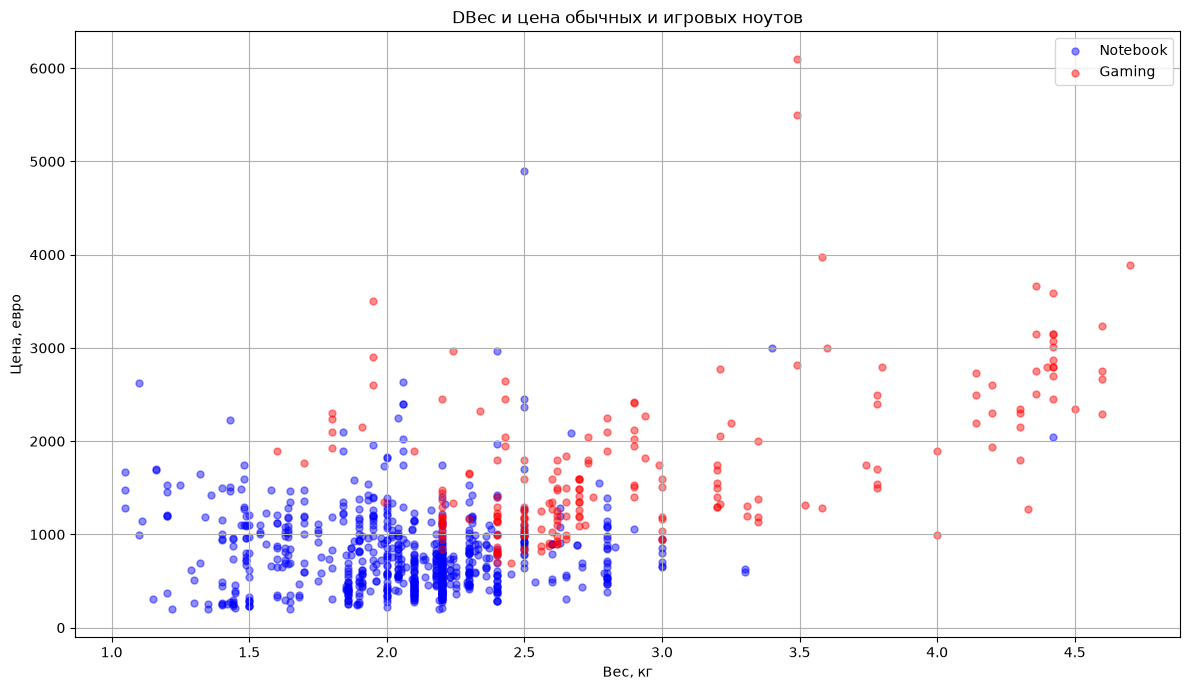

In [75]:
fig, ax = plt.subplots(figsize=(12, 7))
ax.scatter(
    notebooks["Weight_kg"],
    notebooks["Price_euros"],
    s=25,
    alpha=0.45,
    color="blue",
    label="Notebook"
)

ax.scatter(
    gaming_laptops["Weight_kg"],
    gaming_laptops["Price_euros"],
    s=25,
    alpha=0.45,
    color="red",
    label="Gaming"
)
ax.set_title("DВес и цена обычных и игровых ноутов")
ax.set_xlabel("Вес, кг")
ax.set_ylabel("Цена, евро")

ax.legend()
ax.grid(True)
fig.tight_layout()
plt.show()

In [76]:
# seaborn

In [77]:
import seaborn as sns

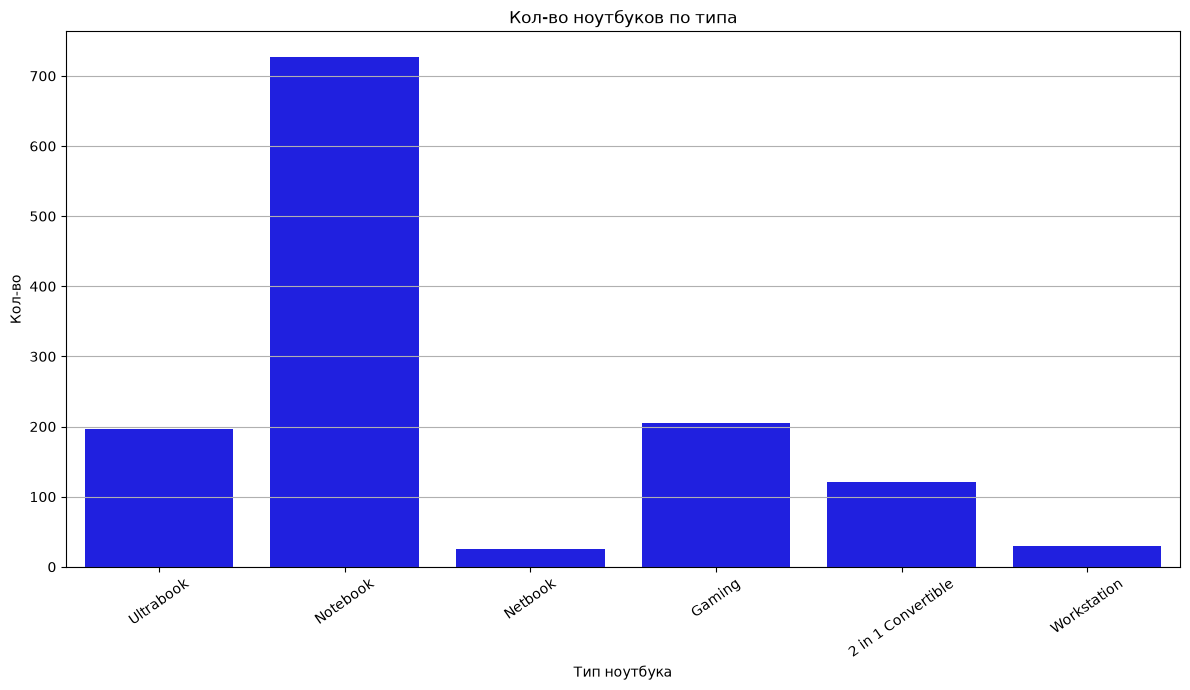

In [79]:
fig, ax = plt.subplots(figsize=(12, 7))
sns.countplot(
    data=df,
    x="TypeName",
    ax=ax,
    color="blue",
)

ax.set_title("Кол-во ноутбуков по типа")
ax.set_xlabel("Тип ноутбука")
ax.set_ylabel("Кол-во")
ax.tick_params(axis="x", labelrotation=35)
ax.grid(True, axis="y")
fig.tight_layout()
plt.show()

In [80]:
# boxplot

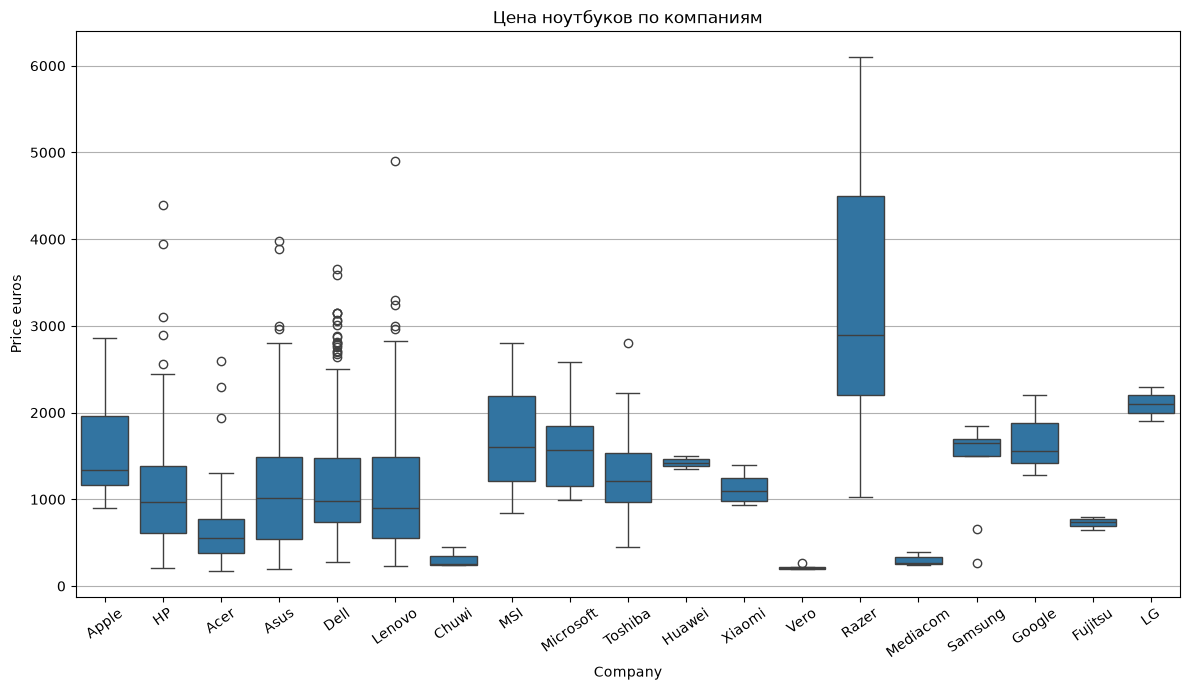

In [81]:
fig, ax = plt.subplots(figsize=(12, 7))
sns.boxplot(
    data=df,
    x="Company",
    y="Price_euros",
)

ax.set_title("Цена ноутбуков по компаниям")
ax.set_xlabel("Company")
ax.set_ylabel("Price euros")
ax.tick_params(axis="x", labelrotation=35)
ax.grid(True, axis="y")
fig.tight_layout()
plt.show()

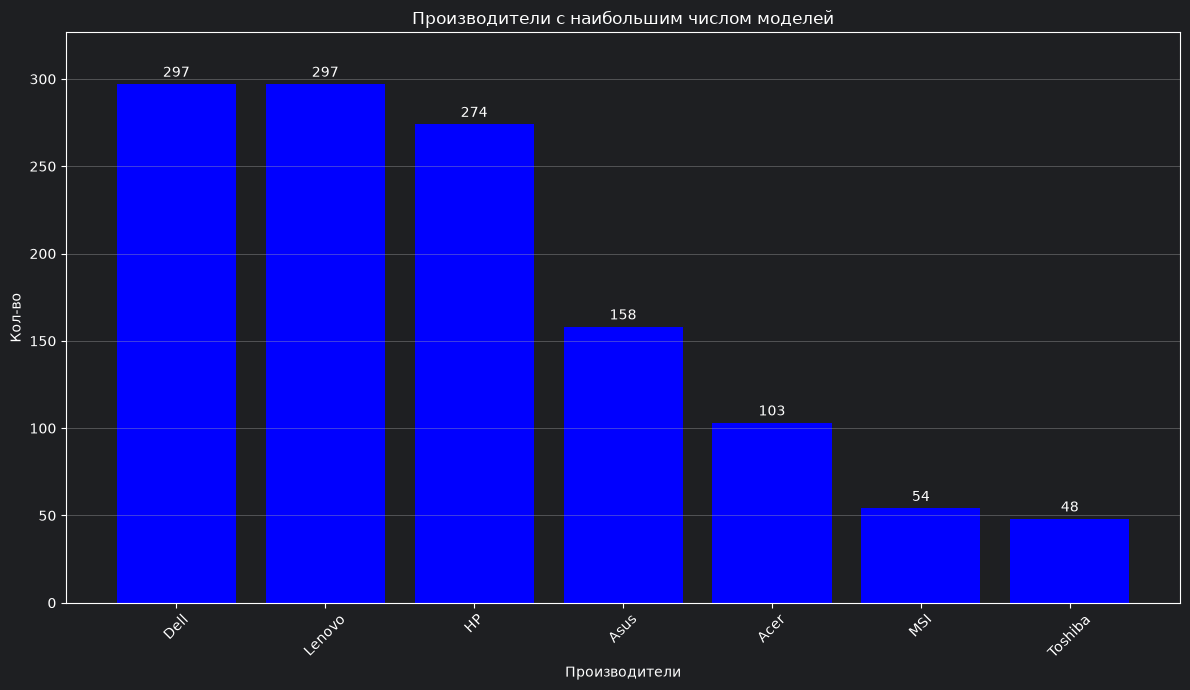

In [86]:
fig, ax = plt.subplots(figsize=(12, 7))

bars = ax.bar(
    top_companies.index,
    top_companies.values,
    color="blue",
)

ax.bar_label(bars, padding=3)

ax.margins(y=0.1)

ax.set_title("Производители с наибольшим числом моделей")
ax.set_xlabel("Производители")
ax.set_ylabel("Кол-во")

ax.tick_params(axis="x", labelrotation=45)
ax.grid(True, axis="y")

# ax.set_yticks(sorted(set(top_companies.values)))

fig.tight_layout()
plt.show()